## **LDA + SVM**

**Import Libraries**

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

**Load Preprocessed Data**

In [ ]:
# Load Dataset
uploaded = files.upload()
file = pd.read_csv('preprocessed_classification.csv')
data_org = pd.DataFrame(file)
data_org.head()

Saving preprocessed_classification.csv to preprocessed_classification.csv


,road_type,num_lanes,curvature,speed_limit,lighting,weather,road_signs_present,public_road,time_of_day,holiday,school_season,num_reported_accidents,accident_risk
0,rural,2,0.29,70,night,rainy,False,True,evening,False,False,1,High
1,highway,1,0.34,25,dim,clear,False,False,morning,False,False,3,Medium
2,rural,2,0.76,70,night,foggy,True,False,evening,True,True,1,High
3,rural,3,0.37,70,night,foggy,True,False,morning,False,True,0,Medium
4,highway,3,0.39,45,dim,rainy,False,True,morning,False,False,0,Low


**Split dataset**

In [ ]:
# Separate feature and label
X = data_org.drop(columns=['accident_risk'])
y = data_org['accident_risk']

In [ ]:
# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
print(y_encoded[:5])

# Encode categorical feature
data_encoded = pd.get_dummies(data_org.drop(columns=['accident_risk']))
print(data_encoded.head())


[0 2 0 2 1]
   num_lanes  curvature  speed_limit  road_signs_present  public_road  \
0          2       0.29           70               False         True   
1          1       0.34           25               False        False   
2          2       0.76           70                True        False   
3          3       0.37           70                True        False   
4          3       0.39           45               False         True   

   holiday  school_season  num_reported_accidents  road_type_highway  \
0    False          False                       1              False   
1    False          False                       3               True   
2     True           True                       1              False   
3    False           True                       0              False   
4    False          False                       0               True   

   road_type_rural  road_type_urban  lighting_daylight  lighting_dim  \
0             True            False         

In [ ]:
# Split Data
X_train, X_test, y_train, y_test = train_test_split(data_encoded, y_encoded,
                                                    test_size = 0.2,
                                                    random_state=42)

**Model Training**

In [ ]:
# standardize features
scale = StandardScaler()
X_train_scale = scale.fit_transform(X_train)
X_test_scale = scale.transform(X_test)

In [ ]:
# Apply LDA
lda = LinearDiscriminantAnalysis(n_components = 2)
# 3 classes -> n_component = 3-1 =2

X_train_lda = lda.fit_transform(X_train_scale,y_train)
X_test_lda = lda.transform(X_test_scale)


In [ ]:
print(X_test_lda.shape)

(19995, 2)


In [ ]:
# Apply SVM (SVC)
model_svm = SVC(probability=True)
model_svm.fit(X_train_lda,y_train)

y_pred = model_svm.predict(X_test_lda)

print(model_svm)

SVC(probability=True)


**Model Evaluation**

In [ ]:
# evaluate accuracy
print("Classification Acuracy: ", accuracy_score(y_test,y_pred))

# classification report
print("\n\nClassification Report")
print(classification_report(y_test,y_pred,
                            target_names=label_encoder.classes_))

Classification Acuracy:  0.8410102525631408


Classification Report
              precision    recall  f1-score   support

        High       0.85      0.62      0.72      2365
         Low       0.82      0.77      0.79      5059
      Medium       0.85      0.91      0.88     12571

    accuracy                           0.84     19995
   macro avg       0.84      0.77      0.80     19995
weighted avg       0.84      0.84      0.84     19995



**Hyperparameter Tuning**

In [ ]:
# Hyperparameter Tuning
kernel = ['linear' , 'rbf' , 'poly'] #rbf
for k in kernel:
  # Apply SVM (SVC)
  model_svm = SVC(kernel=k, probability=True, random_state=42)
  model_svm.fit(X_train_lda,y_train)

  y_pred = model_svm.predict(X_test_lda)
  # evaluate accuracy
  print(f"Classification Acuracy (kernel = {str(k)}): ", accuracy_score(y_test,y_pred))

Classification Acuracy (kernel = linear):  0.8387096774193549
Classification Acuracy (kernel = rbf):  0.8410102525631408
Classification Acuracy (kernel = poly):  0.8357089272318079


In [ ]:
# Hyperparameter Tuning
gamma = [0.001, 0.01, 0.1, 1]  #1
for g in gamma:
  # Apply SVM (SVC)
  model_svm = SVC(kernel='rbf', gamma=g , probability=True, random_state=42)
  model_svm.fit(X_train_lda,y_train)

  y_pred = model_svm.predict(X_test_lda)
  # evaluate accuracy
  print(f"Classification Acuracy (gamma = {g}): ", accuracy_score(y_test,y_pred))

Classification Acuracy (gamma = 0.001):  0.8383095773943486
Classification Acuracy (gamma = 0.01):  0.8385096274068518
Classification Acuracy (gamma = 0.1):  0.839609902475619
Classification Acuracy (gamma = 1):  0.8453613403350838


In [ ]:
# BEST model classification

best_svm = SVC(kernel='rbf', gamma=1, probability=True, random_state=42)
best_svm.fit(X_train_lda,y_train)

y_pred_best = best_svm.predict(X_test_lda)

print(best_svm)

SVC(gamma=1, probability=True, random_state=42)


In [ ]:
# evaluate accuracy
print("Classification Acuracy: ", accuracy_score(y_test,y_pred_best))

# classification report
print("\n\nClassification Report")
print(classification_report(y_test,y_pred_best,
                            target_names=label_encoder.classes_))

Classification Acuracy:  0.8453613403350838


Classification Report
              precision    recall  f1-score   support

        High       0.85      0.64      0.73      2365
         Low       0.82      0.78      0.80      5059
      Medium       0.85      0.91      0.88     12571

    accuracy                           0.85     19995
   macro avg       0.84      0.78      0.80     19995
weighted avg       0.84      0.85      0.84     19995



**Model Visualization**

Confusion Matrix
[[ 1463     0   902]
 [    0  3875  1184]
 [  264   829 11478]]


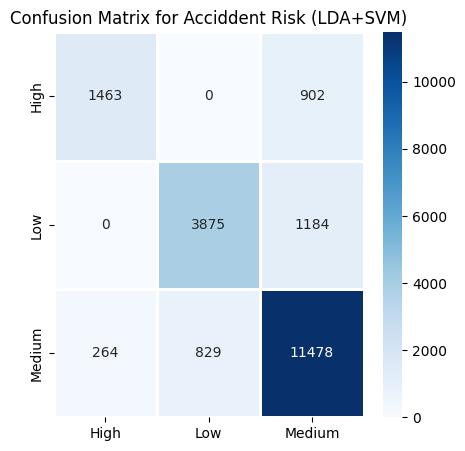

In [ ]:
# Confusion Matrix
print("Confusion Matrix")
matrix = confusion_matrix(y_test,y_pred)
print(matrix)

plt.figure(figsize=(5,5))
sns.heatmap(matrix,
            annot = True,
            cmap = 'Blues',
            linewidths = 1,
            fmt = 'd',
            xticklabels= ['High', 'Low','Medium'],
            yticklabels= ['High', 'Low','Medium'])
plt.title("Confusion Matrix for Acciddent Risk (LDA+SVM)")
plt.show()


Confusion Matrix
[[0.61860465 0.         0.38139535]
 [0.         0.76596165 0.23403835]
 [0.02100072 0.06594543 0.91305385]]


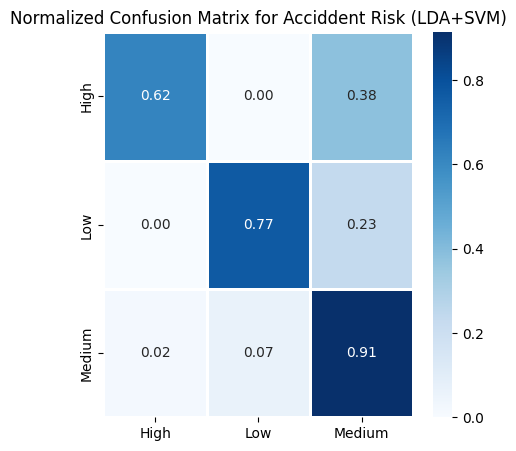

In [ ]:
# Confusion Matrix (normalize)
print("Confusion Matrix")
matrix_nor = confusion_matrix(y_test,y_pred, normalize = 'true')
print(matrix_nor)

plt.figure(figsize=(5,5))
sns.heatmap(matrix_nor,
            annot = True,
            cmap = 'Blues',
            linewidths = 1,
            fmt = '.2f',
            xticklabels= ['High', 'Low','Medium'],
            yticklabels= ['High', 'Low','Medium'])
plt.title("Normalized Confusion Matrix for Acciddent Risk (LDA+SVM)")
plt.show()


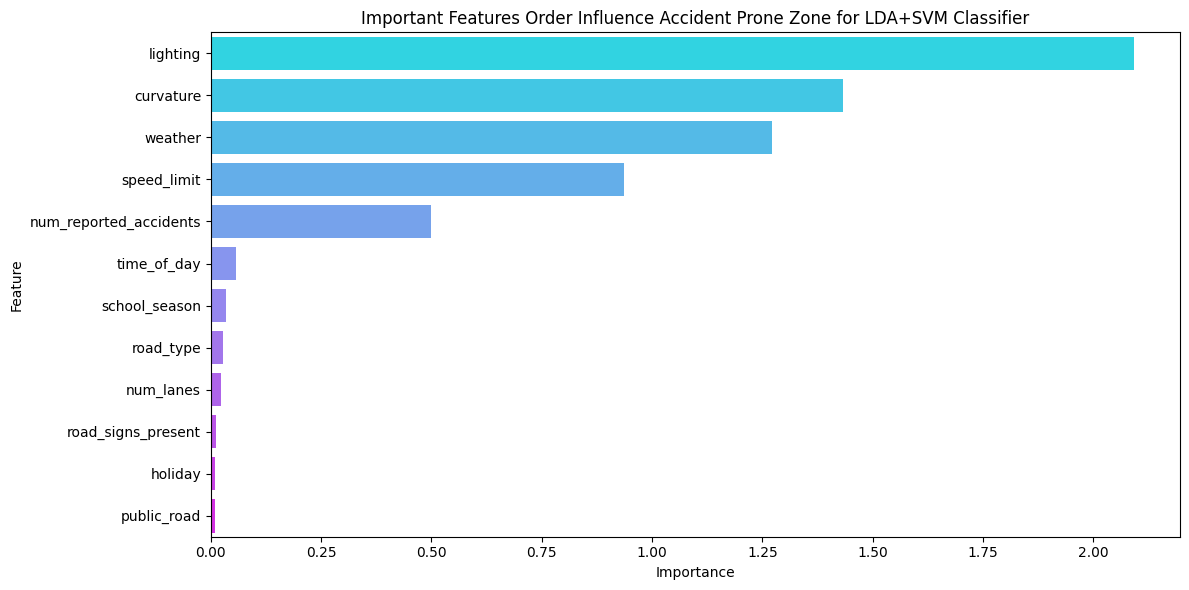

In [ ]:
# Feature Important (use LDA)
lda_coefficient = lda.scalings_

feature_important = pd.DataFrame(np.abs(lda_coefficient),
                                 index = X_train.columns,
                                 columns=[f"LD{i+1}" for i in range(lda_coefficient.shape[1])])
feature_important["importance"] = feature_important.sum(axis=1)

rank_feat = feature_important.sort_values(by="importance",
                                          ascending=False)

# combine those encoded features (
feature_groups = {
    'lighting': ['lighting_daylight', 'lighting_night', 'lighting_dim'],
    'weather': ['weather_clear', 'weather_rainy', 'weather_foggy'],
    'road_type': ['road_type_urban', 'road_type_rural', 'road_type_highway'],
    'time_of_day': ['time_of_day_morning', 'time_of_day_afternoon', 'time_of_day_evening']
}

combine_importance = rank_feat['importance'].copy()

for group, features in feature_groups.items():
    combine_importance[group] = combine_importance[features].sum()
    combine_importance = combine_importance.drop(features)

combine_importance = combine_importance.sort_values(ascending=False)

feature_plot = combine_importance.reset_index()
feature_plot.columns = ['Feature', 'importance']

plt.figure(figsize=(12, 6))
sns.barplot(
    x='importance',
    y='Feature',
    data=feature_plot,
    palette='cool',
    hue = 'Feature'
)

plt.title("Important Features Order Influence Accident Prone Zone for LDA+SVM Classifier")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [ ]:
# Save test data
np.save("X_test_lda.npy", X_test_lda)
np.save("y_test_lda.npy", y_test)

In [ ]:
# Save the lda-svm model
import joblib

joblib.dump(best_svm, 'lda_svm.pkl')

print("Model successfully saved")

Model successfully saved


**ROC Curve (LDA+SVM)**

In [ ]:
import joblib
import numpy as np
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns

In [ ]:
# load model
with open('lda_svm.pkl', 'rb') as file:
    data_lda = joblib.load(file)

print(data_lda)

SVC(gamma=1, probability=True, random_state=42)


In [ ]:
# load LDA test data
X_test_lda = np.load('X_test_lda.npy', allow_pickle=True)
y_test_lda = np.load('y_test_lda.npy', allow_pickle=True)

In [ ]:
print(y_test_lda[:10])
print(y_test_lda.shape)

[1 1 1 2 2 1 2 2 2 0]
(19995,)


In [ ]:
y_pred_lda = data_lda.predict_proba(X_test_lda)

In [ ]:
data_lda.classes_
print(y_pred_lda[:, 0][:10])   # first 10 probabilities for class 0 (low)


[0.00556295 0.02321317 0.00301648 0.05420802 0.02381052 0.00278854
 0.01615022 0.05004988 0.05360059 0.76950861]


In [ ]:
classes = [0, 1, 2]  # Low, Medium, High
y_test_bin = label_binarize(y_test_lda, classes=classes)


In [ ]:
fpr = {}
tpr = {}
roc_auc = {}

for i, class_label in enumerate(classes):
    fpr[class_label], tpr[class_label], _ = roc_curve(
        y_test_bin[:, i],
        y_pred_lda[:, i]
    )
    roc_auc[class_label] = auc(
        fpr[class_label],
        tpr[class_label]
    )


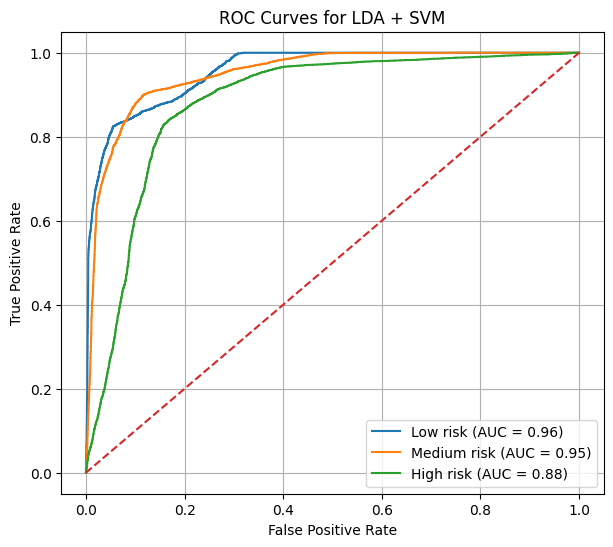

In [ ]:
plt.figure(figsize=(7, 6))

for i, label in enumerate(["Low", "Medium", "High"]):
    plt.plot(
        fpr[i],
        tpr[i],
        label=f"{label} risk (AUC = {roc_auc[i]:.2f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for LDA + SVM")
plt.legend()
plt.grid(True)
plt.show()


**SVM decision region**

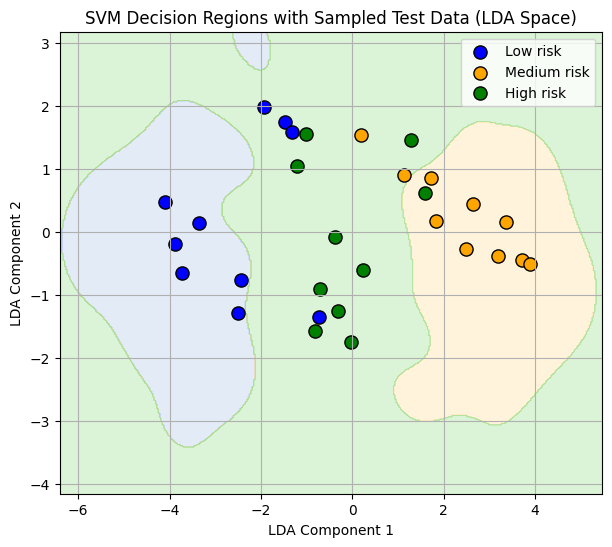

In [ ]:
# Visualize
n_per_class = 10

selected_idx = []

for c in [0, 1, 2]:  # Low, Medium, High
    idx_c = np.where(y_test_lda == c)[0][:n_per_class]
    selected_idx.extend(idx_c)

# take 10 point for each class to visualize
X_test_lda_subset = X_test_lda[selected_idx]
y_test_subset = y_test_lda[selected_idx]



x_min, x_max = X_test_lda[:, 0].min() - 1, X_test_lda[:, 0].max() + 1
y_min, y_max = X_test_lda[:, 1].min() - 1, X_test_lda[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
)


Z = data_lda.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)


# region colors
region_cmap = ListedColormap(["#AEC7E8", "#FFDD99", "#98DF8A"])

# point colors
point_colors = ["blue", "orange", "green"]
labels = ["Low risk", "Medium risk", "High risk"]

plt.figure(figsize=(7, 6))

# plot decision regions
plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.35,
    cmap=region_cmap
)

# plot test points (sample)
for c, label, color in zip([0, 1, 2], labels, point_colors):
    idx = (y_test_subset == c)
    plt.scatter(
        X_test_lda_subset[idx, 0],
        X_test_lda_subset[idx, 1],
        label=label,
        s=90,
        edgecolor="black",
        c=color
    )

plt.xlabel("LDA Component 1")
plt.ylabel("LDA Component 2")
plt.title("SVM Decision Regions with Test Sample Data (LDA Space)")
plt.legend()
plt.grid(True)
plt.show()
